# Internship Dataset Analysis

This notebook analyzes the uploaded `recent_internships.csv` dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

DATA_PATH = Path("/mnt/data/recent_internships.csv")
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 24 rows × 11 columns


,Platform,Role_Title,Company_Name,Domain_Category,Location,Work_Mode,Stipend,Duration,Posted_Date,Required_Skills,Apply_Link
0,Wellfound,Content Writer Intern (Remote),GoPratle,Content Writing,Delhi,Remote,Unpaid,2 Months,2026-11-17,Content Writing; Creative Writing; Copywriting; SEO; Notion; Google Docs,https://wellfound.com/jobs/5094373-content-writer-intern-remote
1,Wellfound,UI/UX Designer - Intern (Remote),GoPratle,Design,Pan India,Remote,"₹2,000 - ₹5,000 /month",Not Disclosed,2026-11-17,UI/UX Design; Figma; Wireframing; Prototyping,https://wellfound.com/jobs/5094373-content-writer-intern-remote
2,Wellfound,Software Engineer Intern,Coy,Software Development,Gurgaon,Hybrid,"₹41,666 /month",6 Months,2026-11-15,JavaScript; React.js; Next.js; Node.js; Express.js; SQL; REST APIs; Git,https://wellfound.com/jobs/5077941-software-engineer-intern
3,Wellfound,Marketing Internship,Coy,Marketing,Gurgaon,In-Office,"₹25,000 - ₹33,333 /month",Not Disclosed,2026-11-15,Digital Marketing; Growth Marketing; Social Media; Brand Strategy,https://wellfound.com/jobs/5077941-software-engineer-intern
4,Wellfound,Institutional Business Development Intern,Locus Learn,Business Development,Noida,Remote,Unpaid,Not Disclosed,2026-11-19,Business Development; B2B Outreach; English Communication; EdTech,https://wellfound.com/jobs/5105627-institutional-business-development-intern...


## 1. Basic dataset inspection

In [ ]:
print("Columns:")
print(list(df.columns))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDomain categories:")
display(df["Domain_Category"].value_counts().to_frame("count"))

Columns:
['Platform', 'Role_Title', 'Company_Name', 'Domain_Category', 'Location', 'Work_Mode', 'Stipend', 'Duration', 'Posted_Date', 'Required_Skills', 'Apply_Link']

Missing values:


,missing_values
Platform,0
Role_Title,0
Company_Name,0
Domain_Category,0
Location,0
Work_Mode,0
Stipend,0
Duration,0
Posted_Date,0
Required_Skills,0



Domain categories:


,count
Domain_Category,
Business Development,4
Artificial Intelligence,3
Data Analytics,3
Finance,3
Sales,2
Content Writing,1
Strategy & Operations,1
Marketing,1
Software Development,1


## 2. Domain classification

The dataset already contains a `Domain_Category` column. We use it to group opportunities into broad areas such as:
- Software Development
- Artificial Intelligence
- Data Analytics
- Cybersecurity
- Finance
- Marketing
- Sales
- Design
- etc.

For a software-focused search, the primary technical domains are **Software Development, Artificial Intelligence, and Data Analytics**.

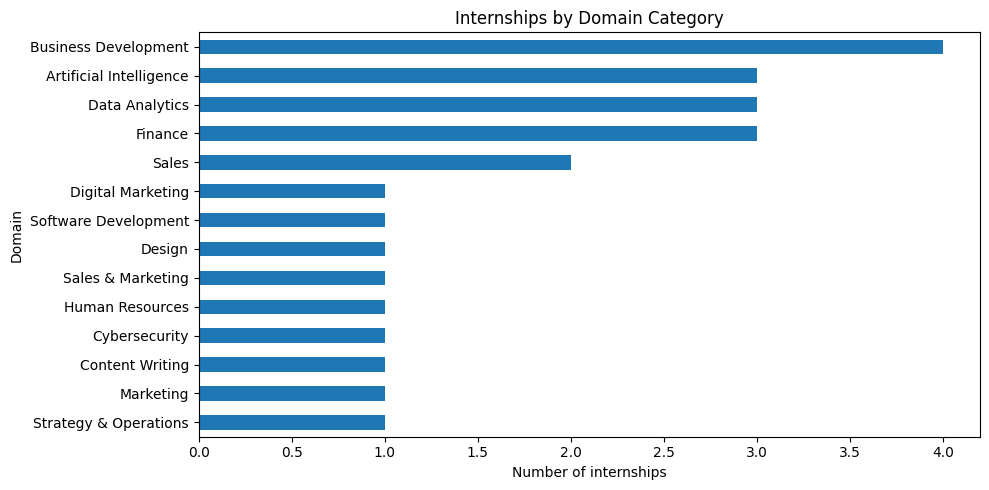

In [ ]:
domain_counts = df["Domain_Category"].value_counts()

plt.figure(figsize=(10, 5))
domain_counts.sort_values().plot(kind="barh")
plt.title("Internships by Domain Category")
plt.xlabel("Number of internships")
plt.ylabel("Domain")
plt.tight_layout()
plt.show()

In [ ]:
display(
    df[["Role_Title", "Company_Name", "Domain_Category", "Location", "Work_Mode", "Stipend"]]
    .sort_values(["Domain_Category", "Role_Title"])
    .reset_index(drop=True)
)

,Role_Title,Company_Name,Domain_Category,Location,Work_Mode,Stipend
0,AI Automation Intern,Partner Company,Artificial Intelligence,Mumbai,In-Office,"₹31,000 /month"
1,RAG Engineer Intern,Partner Company,Artificial Intelligence,Delhi,In-Office,"₹34,000 /month"
2,Speech AI Intern,Partner Company,Artificial Intelligence,Cuttack,In-Office,"₹24,000 /month"
3,Brand Partnerships Intern,VibeSquad,Business Development,Pan India,Remote,"₹12,750 - ₹16,000 /month"
4,Business Development Intern,Shortfundly,Business Development,Pan India,Remote,"₹15,000 - ₹20,000 /month"
5,Business Development Intern,Letzstepin,Business Development,Pan India,Remote,"₹5,000 - ₹10,000 /month"
6,Institutional Business Development Intern,Locus Learn,Business Development,Noida,Remote,Unpaid
7,Content Writer Intern (Remote),GoPratle,Content Writing,Delhi,Remote,Unpaid
8,Malware Analysis Intern,Partner Company,Cybersecurity,Tirunelveli,In-Office,"₹26,000 /month"
9,Power BI Intern,Partner Company,Data Analytics,Anand,In-Office,"₹13,000 /month"


## 3. Software / technical opportunity classification

In [ ]:
technical_domains = {
    "Software Development",
    "Artificial Intelligence",
    "Data Analytics",
    "Cybersecurity"
}

df["Technical_Domain"] = df["Domain_Category"].isin(technical_domains)

software_keywords = [
    "software", "developer", "engineer", "backend", "frontend", "full stack",
    "web", "programming", "api", "developer intern"
]

df["Software_Related"] = (
    df["Role_Title"].str.lower().str.contains("|".join(software_keywords), regex=True, na=False)
    | df["Domain_Category"].eq("Software Development")
)

software_df = df[df["Software_Related"]].copy()

print(f"Software-related opportunities: {len(software_df)}")
display(
    software_df[
        ["Role_Title", "Company_Name", "Domain_Category", "Location", "Work_Mode", "Required_Skills", "Stipend"]
    ].reset_index(drop=True)
)

Software-related opportunities: 2


,Role_Title,Company_Name,Domain_Category,Location,Work_Mode,Required_Skills,Stipend
0,Software Engineer Intern,Coy,Software Development,Gurgaon,Hybrid,JavaScript; React.js; Next.js; Node.js; Express.js; SQL; REST APIs; Git,"₹41,666 /month"
1,RAG Engineer Intern,Partner Company,Artificial Intelligence,Delhi,In-Office,RAG; Vector Databases; Embeddings; Python; LLMs,"₹34,000 /month"


## 4. Location criteria

In [ ]:
# Location preference used for this analysis:
# 1) Delhi / Gurgaon / Noida
# 2) Pan India
# 3) Remote work from any listed location

preferred_city_terms = ["Delhi", "Gurgaon", "Gurugram", "Noida"]
location_text = df["Location"].fillna("").str.lower()

df["Location_Match"] = (
    location_text.str.contains("delhi|gurgaon|gurugram|noida", regex=True)
    | location_text.str.contains("pan india|india", regex=True)
    | df["Work_Mode"].fillna("").str.lower().eq("remote")
)

location_df = df[df["Location_Match"]].copy()

print(f"Location-compatible opportunities: {len(location_df)} / {len(df)}")
display(
    location_df[
        ["Role_Title", "Company_Name", "Location", "Work_Mode", "Domain_Category"]
    ].reset_index(drop=True)
)

Location-compatible opportunities: 15 / 24


,Role_Title,Company_Name,Location,Work_Mode,Domain_Category
0,Content Writer Intern (Remote),GoPratle,Delhi,Remote,Content Writing
1,UI/UX Designer - Intern (Remote),GoPratle,Pan India,Remote,Design
2,Software Engineer Intern,Coy,Gurgaon,Hybrid,Software Development
3,Marketing Internship,Coy,Gurgaon,In-Office,Marketing
4,Institutional Business Development Intern,Locus Learn,Noida,Remote,Business Development
5,Founder's Office Intern (Part-time),Locus Learn,Pan India,Remote,Strategy & Operations
6,Sales & Marketing Intern,Cravely Foods,Maharashtra,Remote,Sales & Marketing
7,HR & Talent Acquisition Intern,Cravely Foods,Pan India,Remote,Human Resources
8,Brand Partnerships Intern,VibeSquad,Pan India,Remote,Business Development
9,Business Development Intern,Shortfundly,Pan India,Remote,Business Development


## 5. Skill criteria

In [ ]:
# Skills relevant to a software / AI / data internship search.
target_skills = {
    "python": ["python"],
    "cpp": ["c++", "cpp"],
    "sql": ["sql"],
    "rest_apis": ["rest api", "rest apis"],
    "git": ["git", "github"],
    "fastapi": ["fastapi"],
    "javascript": ["javascript"],
    "react": ["react", "react.js"],
    "node": ["node", "node.js"],
    "nextjs": ["next.js", "nextjs"],
    "machine_learning": ["machine learning", "deep learning", "xgboost", "sklearn", "scikit"],
    "llm_ai": ["llm", "llms", "rag", "embeddings", "vector databases", "llm apis"],
    "data_analysis": ["data analysis", "pandas", "power bi", "dax", "data visualization"]
}

def matched_skills(skill_text):
    text = str(skill_text).lower()
    matched = []
    for label, keywords in target_skills.items():
        if any(k in text for k in keywords):
            matched.append(label)
    return matched

df["Matched_Skills"] = df["Required_Skills"].apply(matched_skills)
df["Skill_Match_Count"] = df["Matched_Skills"].str.len()

skill_df = df[df["Skill_Match_Count"] > 0].copy()

print(f"Opportunities with at least one target skill: {len(skill_df)}")
display(
    skill_df[
        ["Role_Title", "Company_Name", "Required_Skills", "Matched_Skills", "Skill_Match_Count"]
    ].sort_values("Skill_Match_Count", ascending=False).reset_index(drop=True)
)

Opportunities with at least one target skill: 8


,Role_Title,Company_Name,Required_Skills,Matched_Skills,Skill_Match_Count
0,Software Engineer Intern,Coy,JavaScript; React.js; Next.js; Node.js; Express.js; SQL; REST APIs; Git,"[sql, rest_apis, git, javascript, react, node, nextjs]",7
1,Speech AI Intern,Partner Company,Python; Speech-to-Text; Whisper; Deep Learning,"[python, machine_learning]",2
2,RAG Engineer Intern,Partner Company,RAG; Vector Databases; Embeddings; Python; LLMs,"[python, llm_ai]",2
3,Power BI Intern,Partner Company,Power BI; DAX; Power Query (M); SQL,"[sql, data_analysis]",2
4,SQL Data Analyst Intern,Partner Company,SQL; Joins & Window Functions; Query Optimisation; Data Analysis,"[sql, data_analysis]",2
5,AI Automation Intern,Partner Company,Python; Automation Scripting; LLM APIs; Workflow Automation,"[python, llm_ai]",2
6,Marketing Internship,Coy,Digital Marketing; Growth Marketing; Social Media; Brand Strategy,[git],1
7,Power BI Intern,Partner Company,Power BI; DAX; Power Query (M); Data Visualization,[data_analysis],1


## 6. Skill frequency

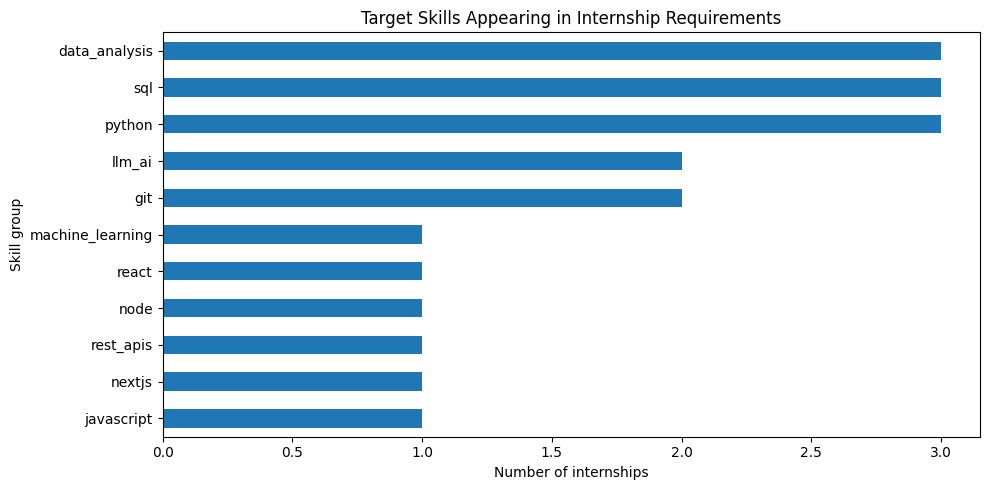

In [ ]:
skill_frequency = {}
for skills in df["Matched_Skills"]:
    for skill in skills:
        skill_frequency[skill] = skill_frequency.get(skill, 0) + 1

skill_frequency = pd.Series(skill_frequency).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
skill_frequency.sort_values().plot(kind="barh")
plt.title("Target Skills Appearing in Internship Requirements")
plt.xlabel("Number of internships")
plt.ylabel("Skill group")
plt.tight_layout()
plt.show()

## 7. Overall match score

A transparent scoring system is used only to **prioritize the rows**; it is not an employer eligibility decision.

- **+3**: Software Development / AI / Data Analytics / Cybersecurity domain
- **+2**: Software-related title
- **+2**: Location/work-mode compatible
- **+1 per matched target skill**, capped at +4
- **+1**: Remote work mode

Interpretation:
- **7+** → Strong match
- **4–6** → Possible match
- **0–3** → Low match

In [ ]:
df["Match_Score"] = 0

df["Match_Score"] += df["Domain_Category"].isin(technical_domains).astype(int) * 3
df["Match_Score"] += df["Software_Related"].astype(int) * 2
df["Match_Score"] += df["Location_Match"].astype(int) * 2
df["Match_Score"] += df["Skill_Match_Count"].clip(upper=4)
df["Match_Score"] += df["Work_Mode"].fillna("").str.lower().eq("remote").astype(int)

def match_label(score):
    if score >= 7:
        return "Strong match"
    elif score >= 4:
        return "Possible match"
    return "Low match"

df["Match_Level"] = df["Match_Score"].apply(match_label)

ranked = df.sort_values(
    ["Match_Score", "Skill_Match_Count", "Posted_Date"],
    ascending=[False, False, False]
)

display(
    ranked[
        ["Role_Title", "Company_Name", "Domain_Category", "Location", "Work_Mode",
         "Matched_Skills", "Match_Score", "Match_Level", "Stipend", "Apply_Link"]
    ].reset_index(drop=True)
)

,Role_Title,Company_Name,Domain_Category,Location,Work_Mode,Matched_Skills,Match_Score,Match_Level,Stipend,Apply_Link
0,Software Engineer Intern,Coy,Software Development,Gurgaon,Hybrid,"[sql, rest_apis, git, javascript, react, node, nextjs]",11,Strong match,"₹41,666 /month",https://wellfound.com/jobs/5077941-software-engineer-intern
1,RAG Engineer Intern,Partner Company,Artificial Intelligence,Delhi,In-Office,"[python, llm_ai]",9,Strong match,"₹34,000 /month",https://myinternships.in/internships
2,Speech AI Intern,Partner Company,Artificial Intelligence,Cuttack,In-Office,"[python, machine_learning]",5,Possible match,"₹24,000 /month",https://myinternships.in/internships
3,Power BI Intern,Partner Company,Data Analytics,Satna,In-Office,"[sql, data_analysis]",5,Possible match,"₹11,000 /month",https://myinternships.in/internships
4,AI Automation Intern,Partner Company,Artificial Intelligence,Mumbai,In-Office,"[python, llm_ai]",5,Possible match,"₹31,000 /month",https://myinternships.in/internships
5,SQL Data Analyst Intern,Partner Company,Data Analytics,Itanagar,In-Office,"[sql, data_analysis]",5,Possible match,"₹14,000 /month",https://myinternships.in/internships
6,Power BI Intern,Partner Company,Data Analytics,Anand,In-Office,[data_analysis],4,Possible match,"₹13,000 /month",https://myinternships.in/internships
7,Marketing Internship,Coy,Marketing,Gurgaon,In-Office,[git],3,Low match,"₹25,000 - ₹33,333 /month",https://wellfound.com/jobs/5077941-software-engineer-intern
8,Sales Intern,Partner Company,Sales,Pan India,Remote,[],3,Low match,"₹8,000 /month",https://myinternships.in/internships
9,Malware Analysis Intern,Partner Company,Cybersecurity,Tirunelveli,In-Office,[],3,Low match,"₹26,000 /month",https://myinternships.in/internships


## 8. Match-level graph

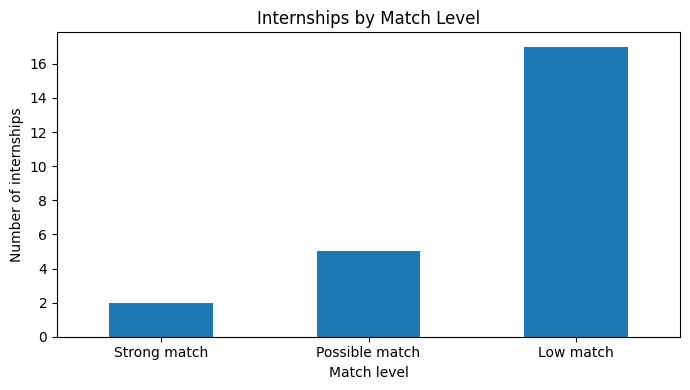

In [ ]:
match_counts = df["Match_Level"].value_counts().reindex(
    ["Strong match", "Possible match", "Low match"], fill_value=0
)

plt.figure(figsize=(7, 4))
match_counts.plot(kind="bar")
plt.title("Internships by Match Level")
plt.xlabel("Match level")
plt.ylabel("Number of internships")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Top opportunities

In [ ]:
top_matches = ranked[ranked["Match_Level"] == "Strong match"].copy()

display(
    top_matches[
        ["Role_Title", "Company_Name", "Domain_Category", "Location", "Work_Mode",
         "Required_Skills", "Matched_Skills", "Match_Score", "Stipend", "Duration", "Apply_Link"]
    ].reset_index(drop=True)
)

,Role_Title,Company_Name,Domain_Category,Location,Work_Mode,Required_Skills,Matched_Skills,Match_Score,Stipend,Duration,Apply_Link
0,Software Engineer Intern,Coy,Software Development,Gurgaon,Hybrid,JavaScript; React.js; Next.js; Node.js; Express.js; SQL; REST APIs; Git,"[sql, rest_apis, git, javascript, react, node, nextjs]",11,"₹41,666 /month",6 Months,https://wellfound.com/jobs/5077941-software-engineer-intern
1,RAG Engineer Intern,Partner Company,Artificial Intelligence,Delhi,In-Office,RAG; Vector Databases; Embeddings; Python; LLMs,"[python, llm_ai]",9,"₹34,000 /month",3 Months,https://myinternships.in/internships


## 10. Technical opportunities by domain

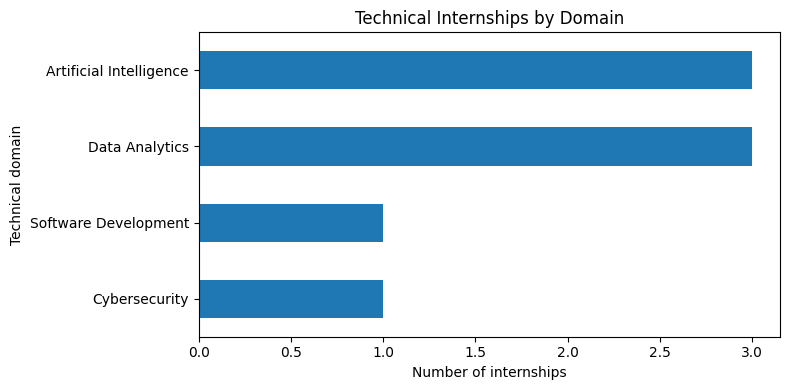

,Role_Title,Company_Name,Domain_Category,Location,Work_Mode,Matched_Skills,Match_Score,Match_Level,Stipend
0,Software Engineer Intern,Coy,Software Development,Gurgaon,Hybrid,"[sql, rest_apis, git, javascript, react, node, nextjs]",11,Strong match,"₹41,666 /month"
1,RAG Engineer Intern,Partner Company,Artificial Intelligence,Delhi,In-Office,"[python, llm_ai]",9,Strong match,"₹34,000 /month"
2,Speech AI Intern,Partner Company,Artificial Intelligence,Cuttack,In-Office,"[python, machine_learning]",5,Possible match,"₹24,000 /month"
3,Power BI Intern,Partner Company,Data Analytics,Satna,In-Office,"[sql, data_analysis]",5,Possible match,"₹11,000 /month"
4,SQL Data Analyst Intern,Partner Company,Data Analytics,Itanagar,In-Office,"[sql, data_analysis]",5,Possible match,"₹14,000 /month"
5,AI Automation Intern,Partner Company,Artificial Intelligence,Mumbai,In-Office,"[python, llm_ai]",5,Possible match,"₹31,000 /month"
6,Power BI Intern,Partner Company,Data Analytics,Anand,In-Office,[data_analysis],4,Possible match,"₹13,000 /month"
7,Malware Analysis Intern,Partner Company,Cybersecurity,Tirunelveli,In-Office,[],3,Low match,"₹26,000 /month"


In [ ]:
technical_df = df[df["Technical_Domain"]].copy()

technical_domain_counts = technical_df["Domain_Category"].value_counts()

plt.figure(figsize=(8, 4))
technical_domain_counts.sort_values().plot(kind="barh")
plt.title("Technical Internships by Domain")
plt.xlabel("Number of internships")
plt.ylabel("Technical domain")
plt.tight_layout()
plt.show()

display(
    technical_df[
        ["Role_Title", "Company_Name", "Domain_Category", "Location", "Work_Mode",
         "Matched_Skills", "Match_Score", "Match_Level", "Stipend"]
    ].sort_values("Match_Score", ascending=False).reset_index(drop=True)
)

## 11. Final filtered shortlist

This is the most useful table for a software-oriented applicant: technical domain + location-compatible + at least one relevant target skill.

In [ ]:
shortlist = df[
    df["Technical_Domain"]
    & df["Location_Match"]
    & (df["Skill_Match_Count"] > 0)
].copy()

shortlist = shortlist.sort_values(
    ["Match_Score", "Skill_Match_Count"], ascending=False
)

print(f"Shortlist size: {len(shortlist)}")

display(
    shortlist[
        ["Role_Title", "Company_Name", "Domain_Category", "Location", "Work_Mode",
         "Required_Skills", "Matched_Skills", "Match_Score", "Match_Level",
         "Stipend", "Duration", "Apply_Link"]
    ].reset_index(drop=True)
)

Shortlist size: 2


,Role_Title,Company_Name,Domain_Category,Location,Work_Mode,Required_Skills,Matched_Skills,Match_Score,Match_Level,Stipend,Duration,Apply_Link
0,Software Engineer Intern,Coy,Software Development,Gurgaon,Hybrid,JavaScript; React.js; Next.js; Node.js; Express.js; SQL; REST APIs; Git,"[sql, rest_apis, git, javascript, react, node, nextjs]",11,Strong match,"₹41,666 /month",6 Months,https://wellfound.com/jobs/5077941-software-engineer-intern
1,RAG Engineer Intern,Partner Company,Artificial Intelligence,Delhi,In-Office,RAG; Vector Databases; Embeddings; Python; LLMs,"[python, llm_ai]",9,Strong match,"₹34,000 /month",3 Months,https://myinternships.in/internships


## 12. Key observations

The notebook's results are calculated directly from the uploaded CSV.

Use the **Strong match** rows as the first review set, then manually check:
1. Exact eligibility requirements.
2. Application deadline / current availability.
3. Whether the listed skills are mandatory or preferred.
4. Work-mode feasibility.
5. Stipend and duration.
6. The actual application page.

The CSV itself does not contain enough information to make a final eligibility decision for a specific applicant.